In [1]:
suppressMessages(library(DESeq2))
suppressMessages(library(ggplot2))
suppressMessages(library(cowplot))
suppressMessages(library(dplyr))
suppressMessages(library(apeglm))
suppressMessages(library(ggrepel))

In [2]:
in_dir <- "../../results/11_compare_with_GSE294965/02_compare"
out_dir <- "../../results/11_compare_with_GSE294965/04_de_analysis"

# create output directory if it doesn't exist
if (!dir.exists(out_dir)) {
   dir.create(out_dir, recursive = TRUE)
}

In [3]:
df_counts <- t(read.csv(glue::glue("{in_dir}/counts_bulk.csv"), row.names = 1, check.names = FALSE))
df_meta <- read.csv(glue::glue("{in_dir}/meta_bulk.csv"), row.names = 1, check.names = FALSE)

In [4]:
head(df_counts)

,X1,X10,X15,X16,X2,X22,X23,X24,X30,X31,⋯,sample_16512,sample_21022,sample_8262,sample_B23-03794-5,sample_B23-05785-7-1,sample_B23-05785-7-2,sample_X1842,sample_X1845,sample_X1899,sample_X1912
ABCC3,3131,3317,2307,4534,1493,2790,1090,4029,2008,4314,⋯,994,495,417,336,988,676,2640,720,2074,15548
ABR,15719,18763,6447,6564,5402,3523,4802,10752,6319,8817,⋯,344,646,87,1354,5712,3314,3868,1564,5016,3743
ACKR3,1931,1146,631,1103,458,1091,696,2194,649,1873,⋯,158,203,53,176,679,520,685,191,400,856
ACSM3,5991,5531,3323,8945,1632,8767,2833,10660,5765,10413,⋯,916,642,88,436,3064,1197,4740,1916,5516,8904
ACTA2,21201,3960,8859,14942,2243,4646,4859,17157,8929,10279,⋯,1792,1434,92,2165,5268,3460,8759,3955,7978,7681
ADAM17,7451,5620,2755,4748,2215,3934,3939,7447,3623,7971,⋯,273,456,111,248,1814,628,2083,688,1614,3202


In [5]:
head(df_meta)

,SampleName,group,data
,<chr>,<chr>,<chr>
X1,sample.X1,Normal,Xenium
X10,sample.X10,Normal,Xenium
X15,sample.X15,LN,Xenium
X16,sample.X16,LN,Xenium
X2,sample.X2,Normal,Xenium
X22,sample.X22,LN,Xenium


In [8]:
# only keep samples in Xenium
df_meta <- df_meta %>% filter(data == "Xenium")
df_meta <- subset(df_meta, group %in% c("Normal", "LN"))

df_counts <- df_counts[, rownames(df_meta)]

In [11]:
head(df_meta)

,SampleName,group,data
,<chr>,<chr>,<chr>
X1,sample.X1,Normal,Xenium
X10,sample.X10,Normal,Xenium
X15,sample.X15,LN,Xenium
X16,sample.X16,LN,Xenium
X2,sample.X2,Normal,Xenium
X22,sample.X22,LN,Xenium


In [12]:
dds <- DESeqDataSetFromMatrix(countData = df_counts,
                              colData = df_meta,
                              design = ~ group)

converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”


In [13]:
keep <- rowSums(counts(dds) >= 10) >= 5
dds <- dds[keep,]

In [14]:
dds

class: DESeqDataSet 
dim: 470 25 
metadata(1): version
assays(1): counts
rownames(470): ABCC3 ABR ... ZEB2 ZNF683
rowData names(0):
colnames(25): X1 X10 ... X8 X9
colData names(3): SampleName group data

In [15]:
dds <- DESeq(dds)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

-- note: fitType='parametric', but the dispersion trend was not well captured by the
   function: y = a/x + b, and a local regression fit was automatically substituted.
   specify fitType='local' or 'mean' to avoid this message next time.

final dispersion estimates

fitting model and testing

-- replacing outliers and refitting for 5 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)

estimating dispersions

fitting model and testing



In [16]:
df_res <- results(dds, contrast = c("group", "LN", "Normal")) %>%
    as.data.frame() %>%
    tidyr::drop_na()

write.csv(df_res, glue::glue("{out_dir}/de_results_LN_vs_Normal.csv"))

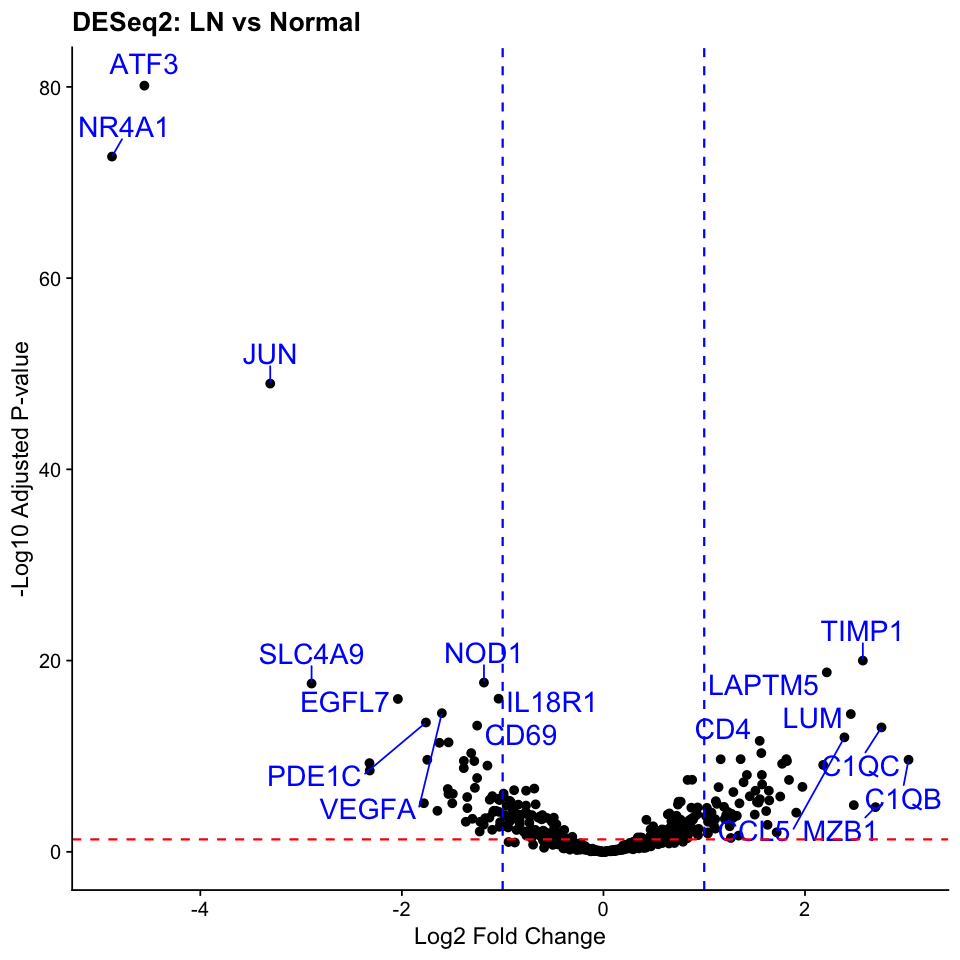

In [17]:
options(repr.plot.width = 8, repr.plot.height = 8)

df_text <- subset(df_res, padj < 0.0001 & abs(log2FoldChange) > 1)

p <- ggplot(data = df_res, aes(x = log2FoldChange, y = -log10(padj))) +
    geom_point() +
    geom_text_repel(data = df_text, aes(label = rownames(df_text)), vjust = -1, size = 6, color = "blue") +
    ggtitle("DESeq2: LN vs Normal") +
    xlab("Log2 Fold Change") +
    ylab("-Log10 Adjusted P-value") +
    geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "red") +
    geom_vline(xintercept = c(-1, 1), linetype = "dashed", color = "blue") +
    theme_cowplot()

print(p)